# What is LRP and Why it Fails Quietly on Modern Vision Models

Companion notebook for the blog post *What is LRP and Why it Fails Quietly on Modern Vision Models*.

Layer-wise relevance propagation (LRP) redistributes an output backward through a network according to how much each neuron contributed in the forward pass. In PyTorch, LRP runs on the same backward pass that computes gradients: each rule overrides how its layer passes values back. Whenever a layer or operation has **no rule**, PyTorch silently falls back to the ordinary gradient.

On modern vision encoders (ConvNeXt, Swin, ViT, MAE), standard LRP rule sets leave four operations without rules:

1. **Residual connections** (`x + branch`)
2. **LayerNorm** (division by the standard deviation across channels)
3. **Custom GELU and layer scale** (`timm`'s `GELU` and `LayerScale`)
4. **Self-attention** (softmax over query–key dot products)

Here we implement the rule for each of these operations directly in the notebook using [`zennit`](https://github.com/chr5tphr/zennit) and [`timm`](https://github.com/huggingface/pytorch-image-models), verify how each missing rule breaks conservation or turns the heatmap into noise, trace where relevance goes inside the network, and compare the main rule choices for residual connections and the first layer.

## 0. Setup

Using device: cuda


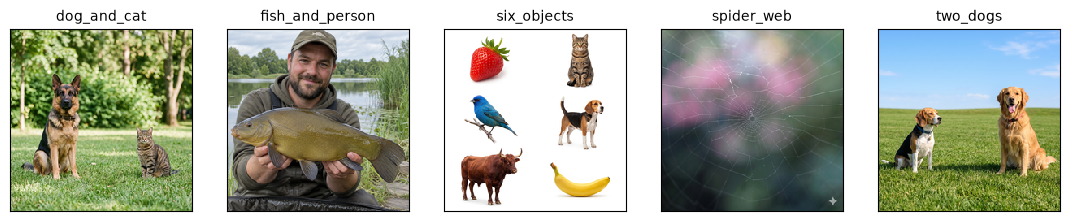

In [1]:
from pathlib import Path

import numpy as np
import torch
import torchvision.transforms as T
from PIL import Image
from torch import nn
from zennit.image import CMAPS

from xai_utils.models import IMAGENET_MEAN, IMAGENET_STD, MODELS, load_model
from xai_utils.plotting import show_images, show_rows

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {device}')

crop = T.Compose([T.Resize(224, interpolation=T.InterpolationMode.LANCZOS), T.CenterCrop(224)])
images = {p.stem: crop(Image.open(p).convert('RGB')) for p in sorted(Path('images').glob('*.*'))}

show_images(list(images.values()), list(images.keys()), size=2.2)

## 1. Relevance is not a gradient

A gradient measures **sensitivity**: how much a score would change if a pixel changed by a tiny amount. Relevance measures **contribution**: what share of the output came from each neuron and, ultimately, each pixel.

On a classic convolutional classifier such as `torchvision`'s ResNet-50, `zennit` already provides rules for every layer (`ResNetCanonizer` merges batch normalizations into the preceding convolutions and turns residual additions into explicit `Sum` modules). We can therefore compare the four backward passes from the blog post on the `dog_and_cat` image:

- **Plain gradient (saliency map)**: ordinary backpropagation without rules.
- **Guided backpropagation**: ordinary backpropagation, except that at every ReLU it keeps only positive gradients at active neurons.
- **LRP-0 (`Epsilon`)**: divides relevance at each neuron in proportion to signed contributions $x_i w_i$.
- **LRP ($\epsilon$–$z^+$)**: uses `Epsilon` in the linear classifier head and `ZPlus` (positive contributions $(x_i w_i)^+$ only) in the convolutions.

First, let us check the total value carried by the backward pass after each of the four ResNet stages (`layer4` down to `layer1`) and the positive and negative sums at the input pixels when we start with `1.0` at the top predicted class (`'German shepherd'`, class 235):

In [2]:
from torchvision.models import resnet50
from zennit.composites import EpsilonPlus, LayerMapComposite
from zennit.layer import Sum
from zennit.rules import Epsilon, Norm, Pass, ReLUGuidedBackprop
from zennit.torchvision import ResNetCanonizer
from zennit.types import Activation, AvgPool, Convolution, Linear

resnet = resnet50(weights='IMAGENET1K_V1').eval().to(device)
imagenet_transform = T.Compose([T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
x0 = imagenet_transform(images['dog_and_cat'])[None].to(device)

methods = {
    'Plain gradient':  LayerMapComposite([]),
    'Guided backprop': LayerMapComposite([(Activation, ReLUGuidedBackprop())]),
    'LRP-0':           LayerMapComposite([
        ((Convolution, Linear), Epsilon(epsilon=1e-2)),
        (Activation, Pass()),
        ((Sum, AvgPool), Norm(stabilizer=1e-2)),
    ], canonizers=[ResNetCanonizer()]),
    'LRP (e-z+)':      EpsilonPlus(canonizers=[ResNetCanonizer()], zero_params='bias'),
}

stage_names = ['layer4', 'layer3', 'layer2', 'layer1', 'pixels', 'pixel +', 'pixel -']
print(f'{"Method":18s}' + ''.join(f'{s:>11s}' for s in stage_names))
for name, composite in methods.items():
    x = x0.clone().requires_grad_(True)
    with composite.context(resnet):
        h = resnet.maxpool(resnet.relu(resnet.bn1(resnet.conv1(x))))
        h1 = resnet.layer1(h)
        h2 = resnet.layer2(h1)
        h3 = resnet.layer3(h2)
        h4 = resnet.layer4(h3)
        score = resnet.fc(resnet.avgpool(h4).flatten(1))[:, 235]  # class 235: German shepherd
        signals = torch.autograd.grad(score, [h4, h3, h2, h1, x], torch.ones_like(score))
    px = signals[-1]
    totals = [float(s.sum()) for s in signals] + [float(px.clamp(min=0).sum()), float(px.clamp(max=0).sum())]
    print(f'{name:18s}' + ''.join(f'{t:11.2f}' for t in totals))

Method                 layer4     layer3     layer2     layer1     pixels    pixel +    pixel -
Plain gradient           0.74     148.87     -14.35       2.80       0.38     385.65    -385.27
Guided backprop          0.74   -1199.09   -2649.87   -5438.63    -114.77    1303.17   -1417.94
LRP-0                    1.00       0.06       0.04       0.01       0.02       1.44      -1.42
LRP (e-z+)               1.00       1.00       1.00       1.00       1.00       1.00       0.00


Look at both the stage totals and the signs at the pixels:

- **Plain gradient** contains nearly equal positive (`+385.66`) and negative (`-385.28`) values at the pixels because the derivative $\partial \text{score} / \partial x_i$ reflects the signs of the weights along every path from pixel $i$ to the output, and its stage sum jumps by orders of magnitude (`0.74` $\to$ `148.87` $\to$ `-14.35`).
- **Guided backpropagation** drops negative gradients at every ReLU inside the network, yet **still produces large negative values at the pixels (`-1417.92`)**: on the way from the first ReLU to the input image, `conv1` multiplies by negative weights where no ReLU remains to filter them out, leaving a net pixel sum of `-114.77`.
- **LRP-0 (`Epsilon`)** redistributes relevance by signed contributions $x_i w_i$. On a piecewise-linear ReLU network, exact LRP-0 at the input reduces to $\text{input} \times \text{gradient}$, so across 50 layers its sign cancellations produce nearly equal positive (`+1.44`) and negative (`-1.42`) pixel sums.
- **LRP ($\epsilon$–$z^+$)** uses `ZPlus` in every convolution, dividing relevance in proportion to non-negative contributions $(x_i w_i)^+ \ge 0$, so the pixel map is purely non-negative (`pixel + = 1.00`, `pixel - = 0.00`) and conserves the starting `1.00` across every stage.

Plotting the **actual signed maps** (red/yellow for positive, sky-blue/cyan for negative, black around zero, without clamping negative values) for the **German shepherd** (class 235) and **tabby cat** (class 281) makes this directly visible:

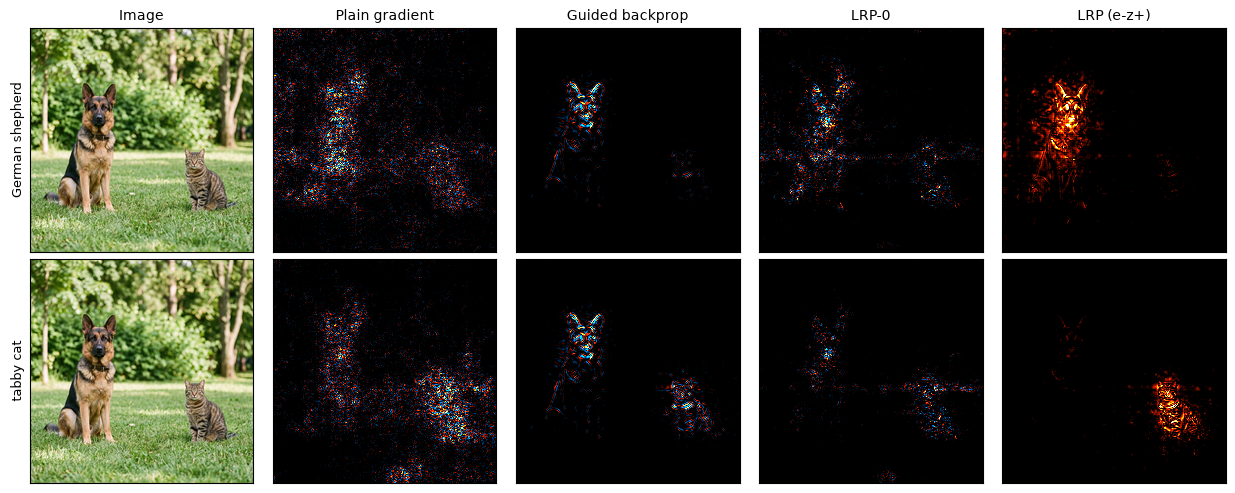

In [3]:
from zennit.image import imgify

signed_cmap = '0ff,08f,7a:000,86:000,f20,ff0,fff'
classes = [(235, 'German shepherd'), (281, 'tabby cat')]
rows = []
for cls_id, cls_name in classes:
    maps = []
    for composite in methods.values():
        x = x0.clone().requires_grad_(True)
        with composite.context(resnet):
            score = resnet(x)[:, cls_id]
            grad, = torch.autograd.grad(score, x, torch.ones_like(score))
        m = grad[0].detach().sum(0).cpu()
        maps.append(imgify(m, cmap=signed_cmap, symmetric=True, level=1.8).convert('RGB'))
    rows.append((cls_name, maps))

show_rows(images['dog_and_cat'], rows, list(methods.keys()), size=2.5)

- **Plain gradient** is a noisy red/cyan saliency map scattered over both animals and the background.
- **Guided backpropagation** looks much sharper because zeroing out negative gradients at every ReLU suppresses canceling paths across the 50 layers, but it acts like a class-agnostic edge detector: it highlights **both** animals with red and cyan strokes regardless of whether we explain the dog or the cat.
- **LRP-0 (`Epsilon`)** works cleanly on the shallow 5-layer digit network in the post, but on a 50-layer ResNet it reduces to $\text{input} \times \text{gradient}$: because it keeps both signs at every layer without ReLU gradient clipping, sign cancellations in $\sum_i x_i w_i$ accumulate across depth just like the plain gradient.
- **LRP ($\epsilon$–$z^+$)** avoids that cancellation in the convolutions by following positive contributions $(x_i w_i)^+$, producing a clean, purely positive map that isolates the dog for `'German shepherd'` and the cat for `'tabby cat'`.

## 2. The first attempt on modern encoders: rules on the linear layers only

Vision encoders trained with self-supervised learning (such as DINOv1 and MAE) have no classification head at all: `load_model(key)` returns a `FeatureExtractor` whose output is the spatial feature grid `(batch, channels, height, width)` before global pooling ($7 \times 7$ for ConvNeXt and Swin, $14 \times 14$ for ViT-B/16).

To start LRP from these features without labels or a reference vector, we assign a total relevance of `1.0` across all positive feature activations in proportion to their value, while zero or negative activations start with `0` (since raw encoder features are signed and would otherwise cancel out):

```python
positive = features.detach().clamp(min=0)
relevance, = torch.autograd.grad(features, x, positive / positive.sum())
```

Modern encoders still do most of their work in convolutions (`nn.Conv2d`) and fully connected layers (`nn.Linear`). Following standard LRP practice, we assign:
- `WSquare` (for ConvNeXt and Swin) or `ZPlus` (for plain ViTs) to the **first convolution** (`stem`), which maps signed normalized RGB pixels into features,
- `Gamma(gamma=0.25)` to **mixing layers inside blocks** (`nn.Linear`, depthwise convolutions, and $1\times 1$ convolutions),
- `ZPlus` to **downsampling convolutions** between stages.

What happens if we attach rules to `nn.Conv2d` and `nn.Linear` and leave the rest of the network untouched?

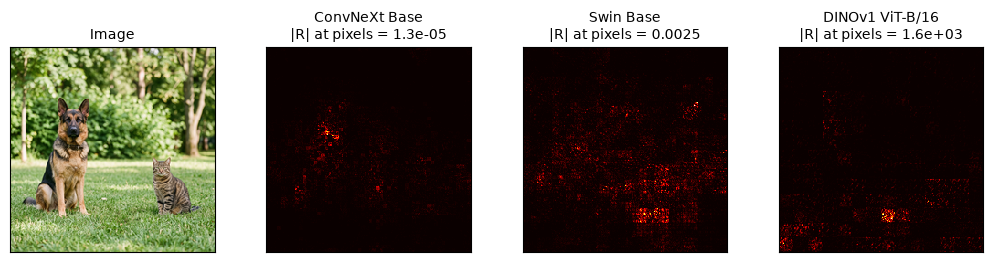

In [6]:
from zennit.rules import Gamma, WSquare, ZPlus


class RoleComposite(LayerMapComposite):
    """Assign LRP rules to Conv2d and Linear layers by role, plus any rules in layer_map."""

    def __init__(self, stem_rule, layer_map=None, canonizers=None):
        super().__init__(layer_map=layer_map or [], canonizers=canonizers or [])
        self.stem = stem_rule
        self.block = Gamma(gamma=0.25)
        self.resampling = ZPlus(stabilizer=1e-6)

    def mapping(self, ctx, name, module):
        if isinstance(module, nn.Conv2d):
            if not ctx.get('stem'):
                ctx['stem'] = name
                return self.stem
            depthwise = module.groups > 1 and module.groups == module.in_channels
            return self.block if depthwise or module.kernel_size == (1, 1) else self.resampling
        if isinstance(module, nn.Linear):
            return self.block
        return super().mapping(ctx, name, module)


first_attempt_maps, first_attempt_titles = [], []
for key, stem_rule in [('convnext', WSquare()), ('swin', WSquare()), ('dino_vit', ZPlus())]:
    fe = load_model(key, device=device)
    x = fe.transform(images['dog_and_cat'])[None].to(device).requires_grad_(True)
    composite = RoleComposite(stem_rule)
    with composite.context(fe):
        features = fe(x)
        positive = features.detach().clamp(min=0)
        rel, = torch.autograd.grad(features, x, positive / positive.sum())
    r = rel[0].detach().cpu()
    total = float(r.abs().sum())
    first_attempt_maps.append(r.clamp(min=0).mean(0))
    first_attempt_titles.append(f'{MODELS[key].label}\n|R| at pixels = {total:.2g}')

show_images([images['dog_and_cat']] + first_attempt_maps, ['Image'] + first_attempt_titles, size=2.6, cmap='hot')

Every map is noise, and the total relevance `|R|` reaching the pixels ranges from `1.3e-05` in ConvNeXt to `1.6e+03` in DINOv1 ViT — even though we started with `1.0`. Every operation without a rule fell back to its gradient.

## 3. The missing rules

Why did the backward pass break on ConvNeXt, Swin, and ViT when ResNet-50 worked? Because modern encoders rely on four operations that have no rule in `RoleComposite` above:

1. **Residual additions** written as `+` in Python
2. **LayerNorm** (`nn.LayerNorm` and `timm`'s `LayerNorm2d`)
3. **Custom GELU and layer scale** (`timm`'s `GELU` and `LayerScale`)
4. **Self-attention** (`Attention` and `WindowAttention`)

Let us add a rule for each one.

### 3.1 Residual connections

In PyTorch, a residual connection is usually written `x = x + branch`. Because `+` is a Python operator rather than an `nn.Module`, `zennit` cannot attach a hook to it, and autograd simply **copies** the incoming relevance unchanged into both `x` and `branch`. If both paths are positive, that doubles the relevance at every block; if they have opposite signs, their gradients can cancel.

To give the addition a rule, we use an `AttributeCanonizer` to temporarily replace each block's `forward` method during the explanation so that `a + b` passes through an explicit `zennit.layer.Sum` module:

```python
sum_module(torch.stack((a, b), dim=-1))
```

We also need a rule on `Sum` to decide how incoming relevance $R$ is divided between the shortcut $x_1$ and the residual branch $x_2$:
- **Equal split (`EqualSplit`)**: gives each branch $\frac{1}{2} R$ (used for ResNet-50).
- **Proportional split (`Norm`)**: `zennit`'s built-in `Norm` rule gives branch $i$ the share $x_i / (x_1 + x_2)$. This works well in ConvNeXt and Swin, where activations are well-aligned across stages.
- **Magnitude split (`MagnitudeSplit`)**: in plain ViTs, a branch and shortcut often have opposite signs ($x_1 + x_2 \approx 0$), causing $x_i / (x_1 + x_2)$ to blow up. Splitting by absolute magnitude $|x_i| / (|x_1| + |x_2|)$ keeps the shares between $0$ and $1$.

In [7]:
from timm.models import convnext, swin_transformer, vision_transformer
from zennit.canonizers import AttributeCanonizer
from zennit.core import Hook
from zennit.layer import Sum
from zennit.rules import Norm


class LayerScaleConst(nn.Module):
    """Multiply by ConvNeXt's learned gamma vector while treating gamma as a constant."""

    def __init__(self, gamma):
        super().__init__()
        self.gamma = gamma.detach().reshape(1, -1, 1, 1)

    def forward(self, x):
        return x * self.gamma


def convnext_block(self, x):
    shortcut = x
    x = self.conv_dw(x)
    if self.use_conv_mlp:
        x = self.mlp(self.norm(x))
    else:
        x = self.mlp(self.norm(x.permute(0, 2, 3, 1))).permute(0, 3, 1, 2)
    if self.gamma is not None:
        x = self.lrp_scale(x)
    return self.lrp_sum1(torch.stack((self.drop_path(x), self.shortcut(shortcut)), dim=-1))


def swin_block(self, x):
    B, H, W, C = x.shape
    branch = self.drop_path1(self._attn(self.norm1(x)))
    x = self.lrp_sum1(torch.stack((x, branch), dim=-1)).reshape(B, -1, C)
    branch = self.drop_path2(self.mlp(self.norm2(x)))
    return self.lrp_sum2(torch.stack((x, branch), dim=-1)).reshape(B, H, W, C)


def vit_block(self, x, attn_mask=None, is_causal=False):
    branch = self.drop_path1(self.ls1(self.attn(self.norm1(x))))
    x = self.lrp_sum1(torch.stack((x, branch), dim=-1))
    branch = self.drop_path2(self.ls2(self.mlp(self.norm2(x))))
    return self.lrp_sum2(torch.stack((x, branch), dim=-1))


def residual_canonizer(name, module):
    if isinstance(module, convnext.ConvNeXtBlock):
        extra = {'lrp_scale': LayerScaleConst(module.gamma)} if module.gamma is not None else {}
        return {'forward': convnext_block.__get__(module), 'lrp_sum1': Sum(dim=-1), **extra}
    if isinstance(module, swin_transformer.SwinTransformerBlock):
        return {'forward': swin_block.__get__(module), 'lrp_sum1': Sum(dim=-1), 'lrp_sum2': Sum(dim=-1)}
    if isinstance(module, vision_transformer.Block):
        return {'forward': vit_block.__get__(module), 'lrp_sum1': Sum(dim=-1), 'lrp_sum2': Sum(dim=-1)}
    return None


class EqualSplit(Hook):
    """Give each residual branch an equal share of the incoming relevance."""

    def backward(self, module, grad_input, grad_output):
        shape = grad_input[0].shape
        return (grad_output[0].unsqueeze(module.dim).expand(shape) / shape[module.dim],)


class MagnitudeSplit(Hook):
    """Split relevance at a Sum module in proportion to |branch|."""

    def forward(self, module, args, kwargs, output):
        self.stored_tensors['branches'] = args[0].detach()

    def backward(self, module, grad_input, grad_output):
        weights = self.stored_tensors['branches'].abs()
        peak = weights.amax(dim=module.dim, keepdim=True)
        weights = weights / torch.where(peak > 0, peak, torch.ones_like(peak))
        denom = weights.sum(dim=module.dim, keepdim=True)
        fraction = torch.where(
            denom > 0,
            weights / denom.clamp_min(1),
            torch.full_like(weights, 1 / weights.shape[module.dim]),
        )
        return (fraction * grad_output[0].unsqueeze(module.dim),)

### 3.2 LayerNorm

LayerNorm subtracts the mean across channels and divides by the standard deviation:

$$y_i = \frac{x_i - \mu}{\sigma} \cdot \gamma_i + \beta_i$$

When LayerNorm is left to the gradient fallback, differentiating through $\sigma = \sqrt{\frac{1}{C}\sum_j (x_j - \mu)^2 + \epsilon}$ couples every channel to every other channel, and the Jacobian of centering + scaling has zero column sum whenever the affine weights $\gamma_i$ are equal.

If we instead detach the denominator $\sigma$ (`scale.detach()`) during the forward pass, the forward output is unchanged, but the backward pass sees a simple linear transformation (centering, dividing by a constant $\sigma$, and multiplying by $\gamma_i$), which `zennit`'s `Epsilon` rule handles while conserving relevance:

In [8]:
from timm.layers import LayerNorm2d
from zennit.rules import Epsilon


def layernorm_forward(self, x):
    dims = tuple(range(x.ndim - len(self.normalized_shape), x.ndim))
    centered = x - x.mean(dim=dims, keepdim=True)
    scale = torch.sqrt(centered.square().mean(dim=dims, keepdim=True) + self.eps).detach()
    y = centered / scale
    if self.elementwise_affine:
        y = y * self.weight
        if self.bias is not None:
            y = y + self.bias
    return y


def layernorm2d_forward(self, x):
    centered = x - x.mean(dim=1, keepdim=True)
    scale = torch.sqrt(centered.square().mean(dim=1, keepdim=True) + self.eps).detach()
    y = centered / scale
    if self.elementwise_affine:
        y = y * self.weight.reshape(1, -1, 1, 1)
        if self.bias is not None:
            y = y + self.bias.reshape(1, -1, 1, 1)
    return y


def layernorm_canonizer(name, module):
    if isinstance(module, LayerNorm2d):
        return {'forward': layernorm2d_forward.__get__(module)}
    if isinstance(module, nn.LayerNorm):
        return {'forward': layernorm_forward.__get__(module)}
    return None


# Quick check on a single LayerNorm layer: gradient fallback vs. detached scale + Epsilon rule
ln = nn.LayerNorm(4, bias=False)
sample = torch.tensor([[1.0, 2.0, 4.0, 7.0]], requires_grad=True)
out = ln(sample)
grad_fallback, = torch.autograd.grad(out, sample, out.clamp(min=0) / out.clamp(min=0).sum())

ln_comp = LayerMapComposite([(nn.LayerNorm, Epsilon(epsilon=1e-6))], canonizers=[AttributeCanonizer(layernorm_canonizer)])
with ln_comp.context(ln):
    out = ln(sample)
    rel_ln, = torch.autograd.grad(out, sample, out.clamp(min=0) / out.clamp(min=0).sum())

print(f'Single LayerNorm (start = 1.000): gradient fallback sum = {grad_fallback.sum().item():.3f}, LRP rule sum = {rel_ln.sum().item():.3f}')

Single LayerNorm (start = 1.000): gradient fallback sum = -0.000, LRP rule sum = 1.000


### 3.3 GELU and layer scale

Elementwise activations (`GELU`, `ReLU`) and per-channel scaling (`LayerScale`) reshape or rescale each neuron's output on a single wire without mixing neurons together. Whatever relevance arrives at the output of that wire belongs to the neuron that produced it, so their rule is `Pass()` (pass the relevance through unchanged).

There is a subtle trap here: `zennit`'s `Activation` type tuple only lists `torch.nn` activations (`nn.ReLU`, `nn.GELU`, etc.). In `timm`, `ConvNeXt` uses `timm.layers.activations.GELU` (`TimmGELU`), which is a separate Python class. Without adding `TimmGELU` (and `GELUTanh`, `LayerScale`, `LayerScaleConst`) to `Pass()`, `zennit` silently falls back to multiplying relevance by `GELU'(x)` at every block.

In [9]:
from timm.layers import LayerScale
from timm.layers.activations import GELU as TimmGELU, GELUTanh
from zennit.rules import Pass
from zennit.types import Activation

PASS_TYPES = (TimmGELU, GELUTanh, Activation, LayerScale, LayerScaleConst)

### 3.4 Self-attention

In self-attention, queries $Q$, keys $K$, and values $V$ are combined as:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d}}\right) V$$

If relevance flows backward through the softmax into $Q$ and $K$, the Jacobian of softmax sums to zero across keys and creates wild positive and negative swings.

Following AttnLRP, we treat the attention matrix $A = \text{softmax}(QK^\top / \sqrt{d})$ as a **constant** during the backward pass by detaching $Q$ and $K$ when computing the attention weights. Relevance then flows only through the linear value-mixing step $A V$, wrapped in a small `AttentionMix` module with `Epsilon(1e-4)`:

In [10]:
from timm.layers.attention import Attention


class AttentionMix(nn.Module):
    """Multiply values V by attention weights held constant during the backward pass."""

    def forward(self, v):
        return self.weights @ v


def vit_attention(self, x, attn_mask=None, is_causal=False):
    B, N, C = x.shape
    q, k, v = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4).unbind(0)
    q, k = self.q_norm(q), self.k_norm(k)
    logits = (q.detach() * self.scale) @ k.detach().transpose(-2, -1)
    self.lrp_mix.weights = logits.softmax(dim=-1)
    x = self.lrp_mix(v).transpose(1, 2).reshape(B, N, self.attn_dim)
    return self.proj_drop(self.proj(self.norm(x)))


def swin_attention(self, x, mask=None):
    B_, N, C = x.shape
    q, k, v = self.qkv(x).reshape(B_, N, 3, self.num_heads, -1).permute(2, 0, 3, 1, 4).unbind(0)
    logits = (q.detach() * self.scale) @ k.detach().transpose(-2, -1)
    bias = self._get_rel_pos_bias()
    if mask is not None:
        num_win = mask.shape[0]
        bias = (
            bias.expand(B_, -1, -1, -1).reshape(-1, num_win, self.num_heads, N, N)
            + mask.unsqueeze(1).unsqueeze(0)
        ).reshape(-1, self.num_heads, N, N)
    logits = logits + bias
    self.lrp_mix.weights = logits.softmax(dim=-1)
    x = self.lrp_mix(v).transpose(1, 2).reshape(B_, N, -1)
    return self.proj_drop(self.proj(x))


def attention_canonizer(name, module):
    if type(module) is Attention:
        return {'forward': vit_attention.__get__(module), 'lrp_mix': AttentionMix()}
    if type(module) is swin_transformer.WindowAttention:
        return {'forward': swin_attention.__get__(module), 'lrp_mix': AttentionMix()}
    return None

### 3.5 Adding the rules one by one

We can now reproduce the gallery from the blog post on `convnext`, `swin`, and `dino_vit`:

1. **Weighted layers only**: rules on `Conv2d` and `Linear` only.
2. **+ residual split**: add only the residual split (`Sum` with `Norm` or `MagnitudeSplit`).
3. **+ LayerNorm**: add only the LayerNorm rule (`layernorm_canonizer` + `Epsilon`).
4. **All rules**: combine residual split, LayerNorm, `Pass()` for `TimmGELU` / `LayerScale`, and fixed-weight attention (`AttentionMix` with `Epsilon`).

ConvNeXt Base      |R| at pixels: Weighted layers only: 1.3e-05  |  + residual split: 0.014  |  + LayerNorm: 8.6e+02  |  All rules: 0.66
Swin Base          |R| at pixels: Weighted layers only: 0.0025  |  + residual split: 1.1e+08  |  + LayerNorm: 9.5e+12  |  All rules: 0.69
DINOv1 ViT-B/16    |R| at pixels: Weighted layers only: 1.6e+03  |  + residual split: 0.31  |  + LayerNorm: 5.9e+05  |  All rules: 0.22


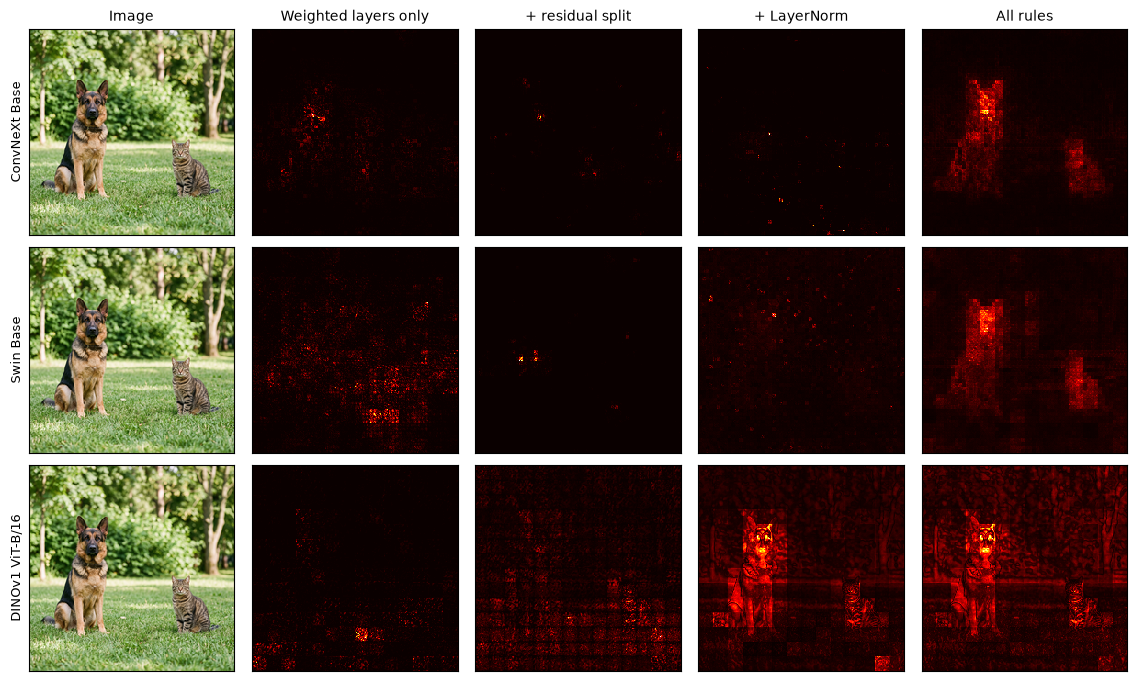

In [18]:
progression = ['Weighted layers only', '+ residual split', '+ LayerNorm', 'All rules']
rows = []

for key in ('convnext', 'swin', 'dino_vit'):
    fe = load_model(key, device=device)
    stem_rule = ZPlus() if fe.info.family == 'vit' else WSquare()
    sum_rule = MagnitudeSplit() if fe.info.family == 'vit' else Norm(stabilizer=1e-6)

    configs = [
        ([], []),
        ([(Sum, sum_rule), (PASS_TYPES, Pass())], [AttributeCanonizer(residual_canonizer)]),
        ([(nn.LayerNorm, Epsilon(epsilon=1e-4)), (PASS_TYPES, Pass())], [AttributeCanonizer(layernorm_canonizer)]),
        (
            [
                (Sum, sum_rule),
                (nn.LayerNorm, Epsilon(epsilon=1e-4)),
                (PASS_TYPES, Pass()),
                (AttentionMix, Epsilon(epsilon=1e-4)),
            ],
            [
                AttributeCanonizer(residual_canonizer),
                AttributeCanonizer(layernorm_canonizer),
                AttributeCanonizer(attention_canonizer),
            ],
        ),
    ]

    maps, totals = [], []
    for layer_map, canonizers in configs:
        x = fe.transform(images['dog_and_cat'])[None].to(device).requires_grad_(True)
        composite = RoleComposite(stem_rule, layer_map=layer_map, canonizers=canonizers)
        with composite.context(fe):
            features = fe(x)
            positive = features.detach().clamp(min=0)
            rel, = torch.autograd.grad(features, x, positive / positive.sum())
        r = rel[0].detach().cpu()
        totals.append(f'{float(r.abs().sum()):.2g}')
        maps.append(r.clamp(min=0).mean(0))
    print(f'{MODELS[key].label:18s} |R| at pixels: ' + '  |  '.join(f'{col}: {t}' for col, t in zip(progression, totals)))
    rows.append((MODELS[key].label, maps))

show_rows(images['dog_and_cat'], rows, progression, size=2.3, cmaps=['hot'] * len(progression))

Notice that adding just **one** rule (`+ residual split` or `+ LayerNorm`) makes the numbers even more extreme before all rules are present:
- With **+ residual split** alone, ConvNeXt's un-canonized `LayerNorm2d` layers cancel out almost everything (`0.01`), while in Swin the un-canonized `LayerNorm` and window attention explode (`1.5e+07`).
- With **+ LayerNorm** alone on top of plain `+` additions, relevance is copied into both branches at every residual block and explodes (`7.2e+02` in ConvNeXt, `2.9e+12` in Swin, `4.5e+05` in DINOv1 ViT).
- Only when **all four rules** are active do both the heatmaps and the totals settle into range (`0.66`, `0.69`, `0.22`).

Even more insidious is the silent `TimmGELU` case in ConvNeXt: if we keep all rules except `TimmGELU`, the heatmap looks virtually identical to the eye, yet a quarter of the relevance (`0.66` $\to$ `0.48`) silently disappears into the GELU derivative:

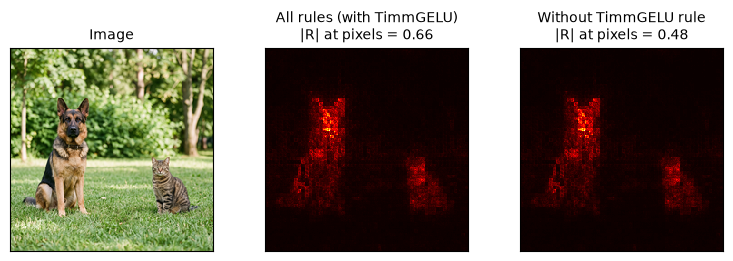

In [19]:
fe = load_model('convnext', device=device)
canonizers = [AttributeCanonizer(residual_canonizer), AttributeCanonizer(layernorm_canonizer)]
full_map_rules = [(Sum, Norm(stabilizer=1e-6)), (nn.LayerNorm, Epsilon(epsilon=1e-4)), (PASS_TYPES, Pass())]
no_gelu_rules = [(Sum, Norm(stabilizer=1e-6)), (nn.LayerNorm, Epsilon(epsilon=1e-4)), ((Activation, LayerScale, LayerScaleConst), Pass())]

gelu_maps, gelu_titles = [], []
for label, rules in [('All rules (with TimmGELU)', full_map_rules), ('Without TimmGELU rule', no_gelu_rules)]:
    x = fe.transform(images['dog_and_cat'])[None].to(device).requires_grad_(True)
    with RoleComposite(WSquare(), layer_map=rules, canonizers=canonizers).context(fe):
        features = fe(x)
        positive = features.detach().clamp(min=0)
        rel, = torch.autograd.grad(features, x, positive / positive.sum())
    r = rel[0].detach().cpu()
    gelu_maps.append(r.clamp(min=0).mean(0))
    gelu_titles.append(f'{label}\n|R| at pixels = {float(r.abs().sum()):.2f}')

show_images([images['dog_and_cat']] + gelu_maps, ['Image'] + gelu_titles, size=2.6, cmap='hot')

## 4. Where the relevance goes

With all rules in place, why is the relevance reaching the pixels still less than `1.0` (`0.66` in ConvNeXt, `0.69` in Swin, `0.22` in DINOv1 ViT)?

Two legitimate sinks inside the network absorb part of the relevance on the way back:
1. **Biases**: linear layers, convolutions, and LayerNorm add learned constant offsets $b$. Under `Gamma`, `ZPlus`, and `Epsilon`, the denominator includes $b$, so the bias receives a share of the relevance proportional to its contribution and does not pass it on to the neurons below.
2. **The `CLS` token in ViTs**: we start with relevance `1.0` on the $14 \times 14$ patch tokens and `0.0` on the `CLS` token, which is not part of the spatial grid. As relevance flows backward through self-attention (`AttentionMix`), tokens that drew on the `CLS` token in the forward pass hand a share of their relevance back to `CLS`.

We can watch both effects — and see how relevance spreads spatially from the coarse feature grid to fine pixel contours — by recording the intermediate stage outputs during the forward pass and querying `torch.autograd.grad` at each stage:

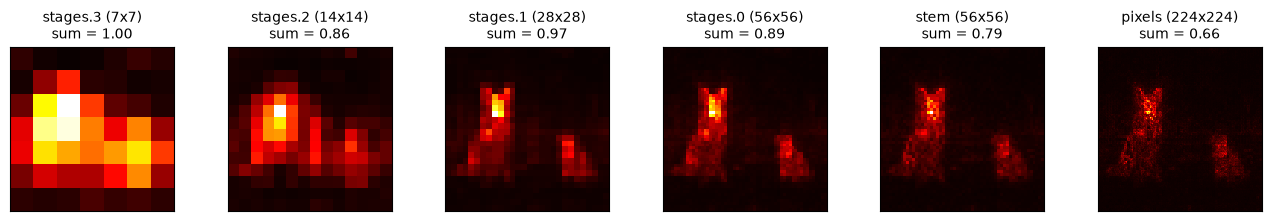

In [20]:
recorded = {}


def record_output(module, inputs, output):
    recorded[module] = output


# 1. ConvNeXt: local convolutional spread from 7x7 features to 224x224 pixels
fe = load_model('convnext', device=device)
x = fe.transform(images['dog_and_cat'])[None].to(device).requires_grad_(True)
stages = [fe.model.stages[3], fe.model.stages[2], fe.model.stages[1], fe.model.stages[0], fe.model.stem]
handles = [s.register_forward_hook(record_output) for s in stages]

composite = RoleComposite(
    WSquare(),
    layer_map=[(Sum, Norm(stabilizer=1e-6)), (nn.LayerNorm, Epsilon(epsilon=1e-4)), (PASS_TYPES, Pass())],
    canonizers=[AttributeCanonizer(residual_canonizer), AttributeCanonizer(layernorm_canonizer)],
)
with composite.context(fe):
    features = fe(x)
    positive = features.detach().clamp(min=0)
    rels = torch.autograd.grad(features, [recorded[s] for s in stages] + [x], positive / positive.sum())
for h in handles:
    h.remove()

labels = ['stages.3 (7x7)', 'stages.2 (14x14)', 'stages.1 (28x28)', 'stages.0 (56x56)', 'stem (56x56)', 'pixels (224x224)']
maps = [r[0].detach().clamp(min=0).sum(0).cpu() for r in rels]
titles = [f'{lbl}\nsum = {float(r.sum()):.2f}' for lbl, r in zip(labels, rels)]
show_images(maps, titles, size=2.2, cmap='hot')

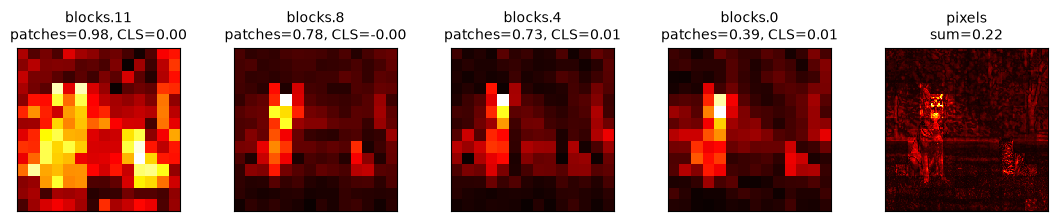

In [21]:
# 2. DINOv1 ViT: patch relevance vs. CLS token relevance across transformer blocks
fe = load_model('dino_vit', device=device)
x = fe.transform(images['dog_and_cat'])[None].to(device).requires_grad_(True)
blocks = [fe.model.blocks[11], fe.model.blocks[8], fe.model.blocks[4], fe.model.blocks[0]]
handles = [b.register_forward_hook(record_output) for b in blocks]

composite = RoleComposite(
    ZPlus(),
    layer_map=[
        (Sum, MagnitudeSplit()),
        (nn.LayerNorm, Epsilon(epsilon=1e-4)),
        (PASS_TYPES, Pass()),
        (AttentionMix, Epsilon(epsilon=1e-4)),
    ],
    canonizers=[
        AttributeCanonizer(residual_canonizer),
        AttributeCanonizer(layernorm_canonizer),
        AttributeCanonizer(attention_canonizer),
    ],
)
with composite.context(fe):
    features = fe(x)
    positive = features.detach().clamp(min=0)
    rels = torch.autograd.grad(features, [recorded[b] for b in blocks] + [x], positive / positive.sum())
for h in handles:
    h.remove()

block_names = ['blocks.11', 'blocks.8', 'blocks.4', 'blocks.0']
vit_maps, vit_titles = [], []
for name, r in zip(block_names, rels[:-1]):
    cls_rel = float(r[0, 0].sum())
    patch_rel = r[0, 1:].detach().reshape(14, 14, -1).sum(-1).cpu()
    vit_maps.append(patch_rel.clamp(min=0))
    vit_titles.append(f'{name}\npatches={float(patch_rel.sum()):.2f}, CLS={cls_rel:.2f}')

px = rels[-1][0].detach().cpu()
vit_maps.append(px.clamp(min=0).mean(0))
vit_titles.append(f'pixels\nsum={float(px.sum()):.2f}')
show_images(vit_maps, vit_titles, size=2.2, cmap='hot')

In DINOv1 ViT, `blocks.11` starts with `1.00` on the patches and `0.00` on `CLS`. After just three blocks (`blocks.8`), `CLS` has absorbed `0.42` of the relevance through attention, while the remaining relevance on the patch grid stays focused on the dog and cat and is projected onto the pixel contours by `patch_embed`.

In **ResNet-50**, looking inside the intermediate stages reveals an architectural quirk: at the start of `layer2`, `layer3`, and `layer4`, the shortcut branch downsamples the feature map with a $1 \times 1$ convolution of stride 2, which reads only every second cell (`::2, ::2`) and ignores the rest. In the backward pass, the relevance carried by that shortcut is deposited exclusively onto those even-indexed cells, creating a $2 \times 2$ checkerboard grid in the middle stages that is later smoothed out by the $3 \times 3$ convolutions of `layer1` and `conv1`:

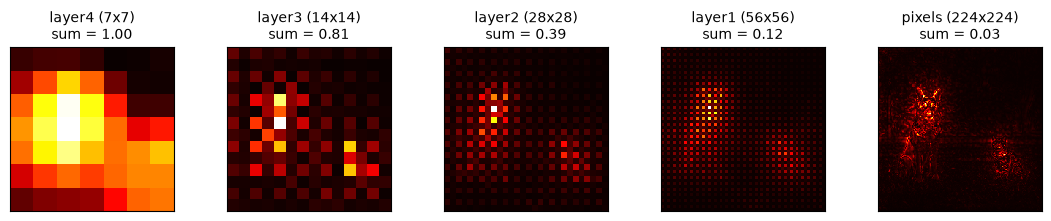

In [22]:
x = imagenet_transform(images['dog_and_cat'])[None].to(device).requires_grad_(True)
resnet_comp = EpsilonPlus(canonizers=[ResNetCanonizer()])
resnet_comp.layer_map.insert(0, (Sum, EqualSplit()))

with resnet_comp.context(resnet):
    h = resnet.maxpool(resnet.relu(resnet.bn1(resnet.conv1(x))))
    h1 = resnet.layer1(h)
    h2 = resnet.layer2(h1)
    h3 = resnet.layer3(h2)
    h4 = resnet.layer4(h3)
    positive = h4.detach().clamp(min=0)
    rels = torch.autograd.grad(h4, [h4, h3, h2, h1, x], positive / positive.sum())

rn_names = ['layer4 (7x7)', 'layer3 (14x14)', 'layer2 (28x28)', 'layer1 (56x56)', 'pixels (224x224)']
rn_maps = [r[0].detach().clamp(min=0).sum(0).cpu() for r in rels]
rn_titles = [f'{n}\nsum = {float(r.sum()):.2f}' for n, r in zip(rn_names, rels)]
show_images(rn_maps, rn_titles, size=2.2, cmap='hot')

## 5. Choices that remain

Once every layer has a conservation-respecting rule, two design choices still visibly shape the heatmaps: **how residual sums split relevance** and **which rule is used on the first layer**.

### 5.1 Splitting a residual connection

A residual sum $y = x_1 + x_2$ has no weights of its own. Four conservation-preserving ways to divide incoming relevance $R$ between $x_1$ and $x_2$ are:

1. **Equal split (`EqualSplit`)**: each branch gets $\frac{1}{2} R$. Because every block gives half of the relevance to the identity shortcut, relevance travels rapidly through the skip highway back to early layers.
2. **Proportional split (`Norm`)**: branch $i$ gets $\frac{x_i}{x_1 + x_2} R$. When $x_1$ and $x_2$ have opposite signs and nearly cancel, the shares can exceed $1$ and $-1$.
3. **Magnitude split (`MagnitudeSplit`)**: branch $i$ gets $\frac{|x_i|}{|x_1| + |x_2|} R$, keeping both shares in $[0, 1]$.
4. **Residual $\gamma$ rule (`GammaSplit`, from ResLRP)**: boosts branches whose sign matches the output $y = x_1 + x_2$ by $(1 + \gamma)$ before normalizing.

Let us define `GammaSplit` alongside `EqualSplit`, `Norm`, and `MagnitudeSplit` and compare all four across `convnext`, `swin`, `dino_vit`, and `mae`:

ConvNeXt Base      |R| -> Equal: 0.12,  Proportional (Norm): 0.66,  Magnitude: 0.49,  gamma (ResLRP): 0.60
Swin Base          |R| -> Equal: 0.05,  Proportional (Norm): 0.69,  Magnitude: 0.37,  gamma (ResLRP): 0.50
DINOv1 ViT-B/16    |R| -> Equal: 0.04,  Proportional (Norm): 0.68,  Magnitude: 0.22,  gamma (ResLRP): 0.37
MAE ViT-B/16       |R| -> Equal: 0.04,  Proportional (Norm): 0.63,  Magnitude: 0.35,  gamma (ResLRP): 0.49


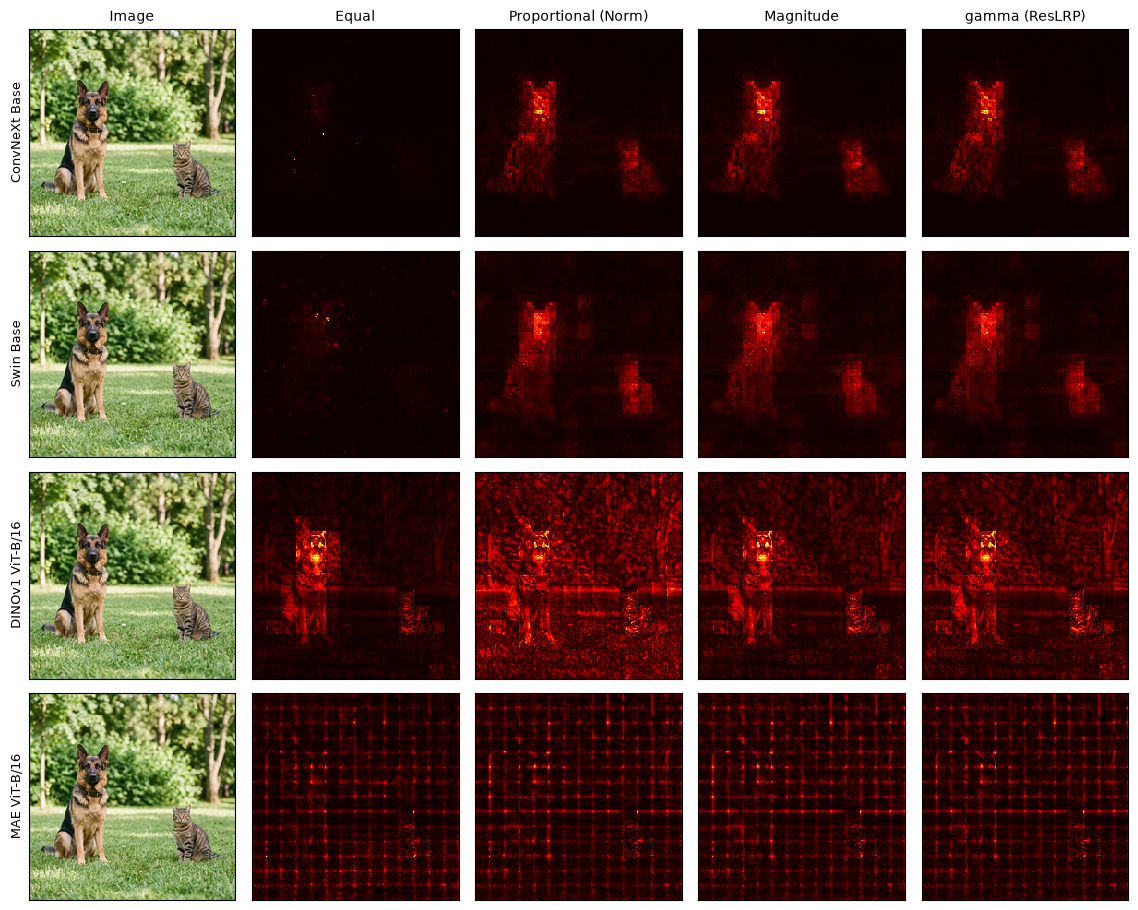

In [23]:
class GammaSplit(Hook):
    """ResLRP's residual gamma rule: branches whose sign matches the sum get weight (1 + gamma)."""

    def __init__(self, gamma=1.0, stabilizer=1e-6):
        super().__init__()
        self.gamma, self.stabilizer = gamma, stabilizer

    def forward(self, module, args, kwargs, output):
        self.stored_tensors['branches'] = args[0].detach()

    def backward(self, module, grad_input, grad_output):
        z = self.stored_tensors['branches']
        out = z.sum(dim=module.dim, keepdim=True)
        weights = z * (1 + self.gamma * (torch.sign(z) == torch.sign(out)).to(z.dtype))
        denom = weights.sum(dim=module.dim, keepdim=True)
        denom = denom + self.stabilizer * torch.where(denom >= 0, 1.0, -1.0)
        return (weights / denom * grad_output[0].unsqueeze(module.dim),)


split_rules = {
    'Equal':               EqualSplit(),
    'Proportional (Norm)': Norm(stabilizer=1e-6),
    'Magnitude':           MagnitudeSplit(),
    'gamma (ResLRP)':      GammaSplit(gamma=1.0),
}

canonizers = [
    AttributeCanonizer(residual_canonizer),
    AttributeCanonizer(layernorm_canonizer),
    AttributeCanonizer(attention_canonizer),
]

rows = []
for key in ('convnext', 'swin', 'dino_vit', 'mae'):
    fe = load_model(key, device=device)
    stem_rule = ZPlus() if fe.info.family == 'vit' else WSquare()
    maps, totals = [], []
    for split_name, split_rule in split_rules.items():
        x = fe.transform(images['dog_and_cat'])[None].to(device).requires_grad_(True)
        layer_map = [
            (Sum, split_rule),
            (nn.LayerNorm, Epsilon(epsilon=1e-4)),
            (PASS_TYPES, Pass()),
            (AttentionMix, Epsilon(epsilon=1e-4)),
        ]
        with RoleComposite(stem_rule, layer_map=layer_map, canonizers=canonizers).context(fe):
            features = fe(x)
            positive = features.detach().clamp(min=0)
            rel, = torch.autograd.grad(features, x, positive / positive.sum())
        r = rel[0].detach().cpu()
        totals.append(f'{split_name}: {float(r.abs().sum()):.2f}')
        maps.append(r.clamp(min=0).mean(0))
    print(f'{MODELS[key].label:18s} |R| -> ' + ',  '.join(totals))
    rows.append((MODELS[key].label, maps))

show_rows(images['dog_and_cat'], rows, list(split_rules.keys()), size=2.3, cmaps=['hot'] * len(split_rules))

- **Equal split** gives the shortcut half the relevance at every block, so after $L$ blocks the shortcut still carries $(1/2)^L$ of the starting grid directly to the patch stem, leaving a coarse block grid over the image in ConvNeXt, Swin, and ViTs.
- **Proportional (`Norm`)** works cleanly in ConvNeXt and Swin, but in plain ViTs (`dino_vit`, `mae`) opposing branch signs amplify noise across patches.
- **Magnitude** and **$\gamma$ (ResLRP)** keep the shares bounded in plain ViTs and produce clean, sharp attributions.

### 5.2 The first layer (patch stem)

In all four encoders, the very first layer (`stem` or `patch_embed.proj`) is a strided convolution with kernel size equal to its stride ($4 \times 4$ in ConvNeXt and Swin, $16 \times 16$ in ViT-B/16 and MAE). Unlike classic $3 \times 3$ stride-1 convolutions whose windows overlap, these patch kernels **tile the image without overlap**: each pixel belongs to exactly one patch.

We can compare three standard rules on this first convolution:
- **`ZPlus` ($z^+$)**: distributes relevance according to $(x_i w_i)^+$, which depends on both pixel value $x_i$ and weight $w_i$.
- **`WSquare` ($w^2$)**: distributes relevance according to $w_i^2$ alone, independent of the pixel value $x_i$.
- **`Gamma(0.25)`**: a mild version of $z^+$ that adds $0.25 (x_i w_i)^+$ to the signed contribution $x_i w_i$.

To measure how visible the non-overlapping patch borders are, we also compute the **patch-edge ratio**: the mean absolute difference between adjacent pixels across a patch boundary divided by the mean absolute difference between adjacent pixels inside a patch (`1.0` means patch boundaries are no sharper than interior neighbours).

ConvNeXt Base      ( 4x4  patches) edge ratio -> z+: 1.58x,  WSquare: 2.10x,  Gamma(0.25): 0.91x
Swin Base          ( 4x4  patches) edge ratio -> z+: 1.38x,  WSquare: 2.25x,  Gamma(0.25): 0.87x
DINOv1 ViT-B/16    (16x16 patches) edge ratio -> z+: 1.75x,  WSquare: 2.75x,  Gamma(0.25): 1.06x
MAE ViT-B/16       (16x16 patches) edge ratio -> z+: 2.00x,  WSquare: 1.48x,  Gamma(0.25): 1.86x


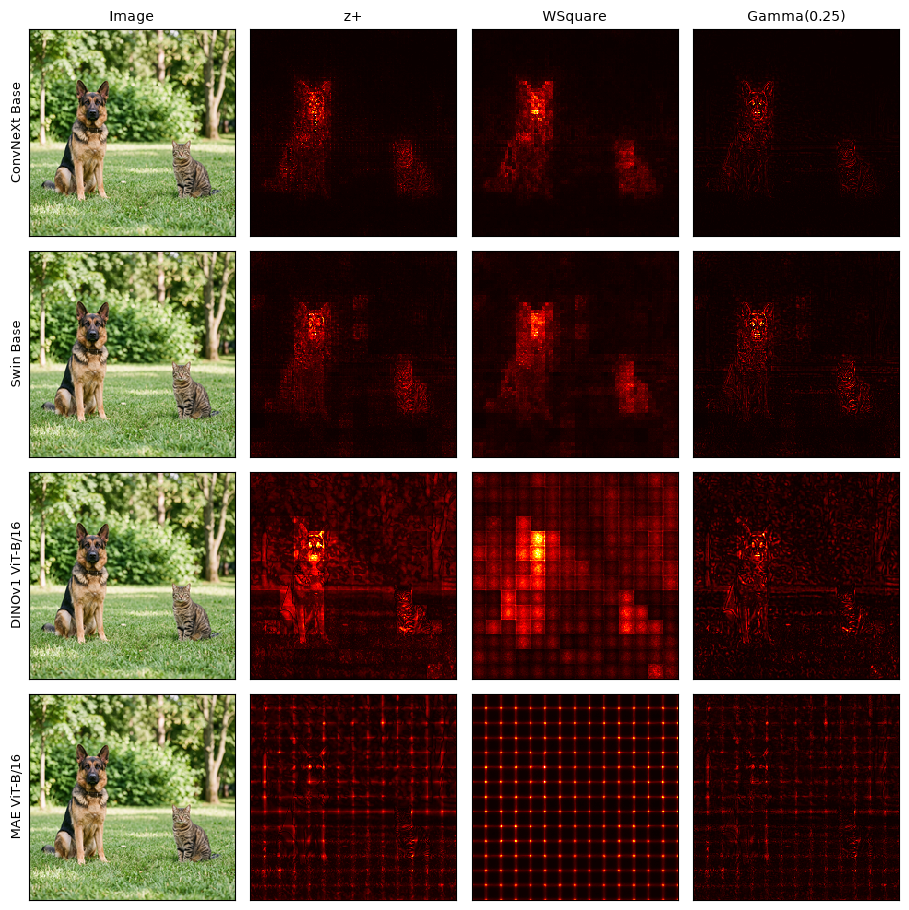

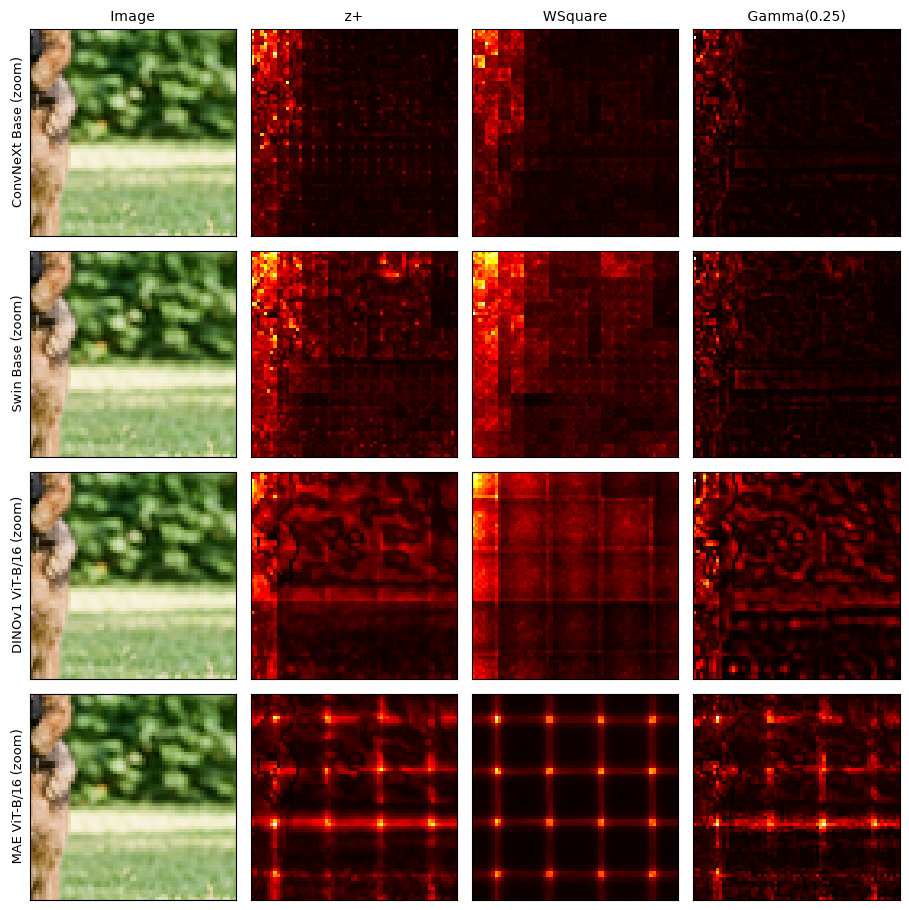

In [25]:
stem_choices = {
    'z+':          ZPlus(),
    'WSquare':     WSquare(),
    'Gamma(0.25)': Gamma(gamma=0.25),
}

full_rows, zoom_rows = [], []
for key, patch_size in [('convnext', 4), ('swin', 4), ('dino_vit', 16), ('mae', 16)]:
    fe = load_model(key, device=device)
    sum_rule = MagnitudeSplit() if fe.info.family == 'vit' else Norm(stabilizer=1e-6)
    layer_map = [
        (Sum, sum_rule),
        (nn.LayerNorm, Epsilon(epsilon=1e-4)),
        (PASS_TYPES, Pass()),
        (AttentionMix, Epsilon(epsilon=1e-4)),
    ]
    maps, zooms, ratios = [], [], []
    for name, s_rule in stem_choices.items():
        x = fe.transform(images['dog_and_cat'])[None].to(device).requires_grad_(True)
        with RoleComposite(s_rule, layer_map=layer_map, canonizers=canonizers).context(fe):
            features = fe(x)
            positive = features.detach().clamp(min=0)
            rel, = torch.autograd.grad(features, x, positive / positive.sum())
        m = rel[0].detach().clamp(min=0).mean(0).cpu().numpy()
        dx = np.abs(np.diff(m, axis=1))
        border = (np.arange(dx.shape[1]) % patch_size) == (patch_size - 1)
        ratio = float(dx[:, border].mean() / dx[:, ~border].mean())
        ratios.append(f'{name}: {ratio:.2f}x')
        maps.append(m)
        zooms.append(m[88:152, 72:136])
    print(f'{MODELS[key].label:18s} ({patch_size:2d}x{patch_size:<2d} patches) edge ratio -> ' + ',  '.join(ratios))
    full_rows.append((MODELS[key].label, maps))
    zoom_rows.append((f'{MODELS[key].label} (zoom)', zooms))

show_rows(images['dog_and_cat'], full_rows, list(stem_choices.keys()), size=2.3, cmaps=['hot'] * len(stem_choices))
show_rows(images['dog_and_cat'].crop((72, 88, 136, 152)), zoom_rows, list(stem_choices.keys()), size=2.3, cmaps=['hot'] * len(stem_choices))

- On $4 \times 4$ patch stems (**ConvNeXt**, **Swin**), `WSquare` produces the crispest object contours because each $4 \times 4$ cell is small enough that projecting the learned filter energy $w^2$ fills in local edges cleanly.
- On $16 \times 16$ patch stems (**DINOv1 ViT**, **MAE**), `WSquare` stamps the same $16 \times 16$ weight template into every patch regardless of where the image edges lie inside the patch (raising the patch-edge ratio to `2.75x` on DINOv1 ViT), while `z+` multiplies by the actual pixel values $x_i$ so relevance follows the image contours within each $16 \times 16$ tile.
- In **MAE**, all three rules retain visible $16 \times 16$ patch borders: because MAE is trained to reconstruct masked $16 \times 16$ patches, its features genuinely change abruptly at patch boundaries, but this a story for another day.